# Q-Learning en Taxi-v4 resuelto (trabajo en casa)

**Juan David Sierra Orozco**
Inteligencia Artificial (SI3003), EAFIT

Notebook del trabajo en casa de la clase 5 con las tres actividades de código implementadas (`choose_action`, `update_q`, `train_q_learning`), la curva de aprendizaje, la comparación antes y después, el análisis de una fila de Q, el experimento de hiperparámetros y las siete preguntas respondidas. Las respuestas están en celdas de texto marcadas como **Respuesta**; donde dependen de números, hay una celda de código que los calcula.

**Reproducibilidad.** Se fijan las semillas de `random`, `np.random` y del ambiente. Las celdas de análisis que agregué corren dentro de `aislado()`, que guarda y restaura el estado de los generadores globales para que verificar algo no cambie los números de las celdas siguientes. Las funciones de visualización del enunciado no se modificaron.

---

# 🚕 Q-Learning en Taxi-v4 - Trabajo en casa

En este ejercicio aplicará Q-Learning al ambiente **Taxi-v4** de Gymnasium.

La lógica es la misma trabajada en FrozenLake:

$$
(s_t,a_t) \rightarrow (r_{t+1},s_{t+1})
$$

y la actualización:

$$
Q(s_t,a_t)
\leftarrow
Q(s_t,a_t)
+
\alpha
\left[
r_{t+1}
+
\gamma \max_a Q(s_{t+1},a)
-
Q(s_t,a_t)
\right]
$$

## Objetivo

Implementar y analizar un agente Q-Learning capaz de aprender a recoger un pasajero y llevarlo a su destino.


## 1. Preparación

Instale Gymnasium si es necesario:

```bash
pip install gymnasium[toy-text]
```


In [1]:
import gymnasium as gym
import numpy as np
import random
import matplotlib.pyplot as plt

from IPython.display import HTML
from matplotlib import animation


### Semillas y utilidad para aislar el azar

In [2]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

import contextlib

@contextlib.contextmanager
def aislado():
    """Ejecuta un bloque sin alterar los generadores aleatorios globales.

    Guarda el estado de `random` y de `np.random`, deja correr el bloque y lo
    restaura al salir. Así una celda de verificación o de análisis no cambia
    los números que verán las celdas posteriores."""
    estado_py = random.getstate()
    estado_np = np.random.get_state()
    try:
        yield
    finally:
        random.setstate(estado_py)
        np.random.set_state(estado_np)

## 2. Crear el ambiente

Taxi tiene un número de estados mucho mayor que FrozenLake.

Cada estado codifica:

- posición del taxi,
- ubicación del pasajero,
- destino del pasajero.

Las acciones posibles son:

| Acción | Significado |
|---|---|
| 0 | South |
| 1 | North |
| 2 | East |
| 3 | West |
| 4 | Pickup |
| 5 | Dropoff |


In [3]:
env = gym.make("Taxi-v4", render_mode="rgb_array")

print("Número de estados:", env.observation_space.n)
print("Número de acciones:", env.action_space.n)

env.reset(seed=SEED)
env.action_space.seed(SEED)

Número de estados: 500
Número de acciones: 6


42

### Pregunta 1

¿Cuántos estados y cuántas acciones tiene Taxi-v4?

Explique brevemente por qué Taxi tiene muchos más estados que FrozenLake.


In [4]:
print("Estados :", env.observation_space.n)
print("Acciones:", env.action_space.n)
print("Descomposición:", "25 posiciones del taxi x 5 ubicaciones del pasajero x 4 destinos =", 25*5*4)
print("FrozenLake 4x4 tiene solo", 16, "estados")

Estados : 500
Acciones: 6
Descomposición: 25 posiciones del taxi x 5 ubicaciones del pasajero x 4 destinos = 500
FrozenLake 4x4 tiene solo 16 estados


**Respuesta.** Taxi-v4 tiene **500 estados** y **6 acciones** (South, North, East, West, Pickup, Dropoff).

Tiene muchos más estados que FrozenLake (que solo tiene 16) porque en FrozenLake el estado es únicamente *la posición del agente*, mientras que en Taxi el estado **codifica tres cosas a la vez**: dónde está el taxi (25 casillas de un mapa 5x5), dónde está el pasajero (5 posibilidades: las cuatro estaciones R, G, Y, B o dentro del taxi) y cuál es el destino (4 estaciones). Los estados se multiplican: $25\times5\times4=500$. Además, las acciones pasan de 4 a 6 porque aparecen Pickup y Dropoff.

## 3. Observar una interacción

Ejecute una acción aleatoria y observe qué devuelve el ambiente.


In [5]:
state, info = env.reset(seed=42)

action = env.action_space.sample()

next_state, reward, terminated, truncated, info = env.step(action)

print("Estado:", state)
print("Acción:", action)
print("Nuevo estado:", next_state)
print("Recompensa:", reward)
print("Terminated:", terminated)


Estado: 386
Acción: 0
Nuevo estado: 486
Recompensa: -1
Terminated: False


### Pregunta 2

En la interacción anterior identifique:

$$
s_t,\quad a_t,\quad r_{t+1},\quad s_{t+1}
$$

¿Qué representa cada elemento?


In [6]:
print(f"s_t = {state}   a_t = {action}   r_t+1 = {reward}   s_t+1 = {next_state}")
# Decodificación legible del estado con el método del propio ambiente
fila_taxi, col_taxi, pasajero, destino = env.unwrapped.decode(state)
print("Estado s_t decodificado   -> taxi en (fila, col) =", (fila_taxi, col_taxi), "| pasajero:", pasajero, "| destino:", destino)
fila_taxi, col_taxi, pasajero, destino = env.unwrapped.decode(next_state)
print("Estado s_t+1 decodificado -> taxi en (fila, col) =", (fila_taxi, col_taxi), "| pasajero:", pasajero, "| destino:", destino)

s_t = 386   a_t = 0   r_t+1 = -1   s_t+1 = 486
Estado s_t decodificado   -> taxi en (fila, col) = (3, 4) | pasajero: 1 | destino: 2
Estado s_t+1 decodificado -> taxi en (fila, col) = (4, 4) | pasajero: 1 | destino: 2


**Respuesta.** En la interacción de la celda (semilla 42, acción aleatoria):

- $s_t = 386$: el **estado** antes de actuar. Decodificado: el taxi está en la fila 3, columna 4, el pasajero está en la estación 1 (Green) y el destino es la estación 2 (Yellow).
- $a_t = 0$: la **acción** ejecutada, South (bajar una fila).
- $r_{t+1} = -1$: la **recompensa** que devolvió el ambiente. Taxi cobra -1 por cada paso, -10 por un Pickup o Dropoff ilegal y +20 por entregar al pasajero. Un movimiento normal vale -1.
- $s_{t+1} = 486$: el **nuevo estado**. El taxi bajó a la fila 4, columna 4; el pasajero y el destino no cambiaron, solo la posición del taxi.

`Terminated = False` porque el episodio sigue: el pasajero todavía no fue entregado.

## 4. Inicializar la Q-table

Cada fila corresponde a un estado y cada columna a una acción.

Inicialmente:

$$
Q(s,a)=0
$$


In [7]:
n_states = env.observation_space.n
n_actions = env.action_space.n

Q = np.zeros((n_states, n_actions))

print("Shape de Q:", Q.shape)
Q[:5]


Shape de Q: (500, 6)


array([[0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0.]])

### Pregunta 3

¿Cuántos valores debe aprender el agente en total?

Calcule:

$$
|\mathcal{S}| \times |\mathcal{A}|
$$


In [8]:
print("Valores totales por aprender:", n_states, "x", n_actions, "=", n_states * n_actions)

Valores totales por aprender: 500 x 6 = 3000


**Respuesta.** El agente debe aprender
$$|\mathcal{S}|\times|\mathcal{A}| = 500\times6 = 3000$$
valores $Q(s,a)$. Es 47 veces más que los 64 de FrozenLake (la celda de arriba imprime 500 x 6 = 3000), y por eso se necesitan miles de episodios para que cada pareja se visite varias veces.

## 5. Política $\epsilon$-greedy

Implemente una función que:

- con probabilidad $\epsilon$ seleccione una acción aleatoria;
- en otro caso seleccione:

$$
\arg\max_a Q(s,a)
$$

### Actividad 1
Complete la función.


In [9]:
def choose_action(Q, state, epsilon, env):
    # 1. decidir si explorar o explotar
    if random.random() < epsilon:
        # explorar: acción aleatoria válida del ambiente
        return env.action_space.sample()
    # 2. explotar: argmax_a Q(s,a), con desempate al azar entre acciones empatadas
    #    (con la Q-table en cero todas empatan; un argmax a secas elegiría siempre la acción 0)
    q_values = Q[state]
    mejores = np.flatnonzero(q_values == np.max(q_values))
    return int(np.random.choice(mejores))

**Respuesta.** `choose_action` implementa $\epsilon$-greedy. Con probabilidad $\epsilon$ devuelve `env.action_space.sample()` (explorar). En otro caso devuelve $\arg\max_a Q(s,a)$, pero con **desempate aleatorio** entre las acciones que comparten el valor máximo. Esto es importante en Taxi: al comienzo toda la fila vale 0, y un `np.argmax` a secas devolvería siempre la acción 0 (South) en los estados nuevos, sesgando la exploración. El desempate es el mismo que usa `play_episode`.

## 6. Actualización de Q

La regla de actualización es:

$$
Q(s,a)
\leftarrow
Q(s,a)
+
\alpha
\left[
r+
\gamma\max_{a'}Q(s',a')
-
Q(s,a)
\right]
$$

### Actividad 2
Complete la función.


In [10]:
def update_q(Q, state, action, reward, next_state, alpha, gamma):
    # Calcular el target:  r + gamma * max_a' Q(s', a')
    # (en un estado terminal la fila de Q nunca se actualiza y vale 0, así que max = 0 sin tratamiento especial)
    td_target = reward + gamma * np.max(Q[next_state])
    # Calcular el error TD:  target - estimación actual
    td_error = td_target - Q[state, action]
    # Actualizar Q[state, action]
    Q[state, action] += alpha * td_error
    return td_error

**Respuesta.** `update_q` aplica la regla de Q-Learning en tres pasos: calcula el *target* $r+\gamma\max_{a'}Q(s',a')$, el *error TD* (target menos la estimación actual) y mueve $Q(s,a)$ una fracción $\alpha$ de ese error. Devuelve el error TD para poder inspeccionarlo.

No se necesita una bandera `done` en la firma dada, porque en un estado terminal (pasajero ya entregado) el agente nunca actúa, así que su fila de Q nunca se actualiza y se queda en 0: el `max` da 0, que es justamente el valor futuro correcto al terminar. La celda de verificación comprueba una actualización calculada a mano: con $r=-1$, $\gamma=0.9$, $\max Q(s',\cdot)=2$, $\alpha=0.5$ el target es 0.8 y $Q$ pasa de 0 a 0.4.

In [11]:
# Verificación a mano de update_q (aislado y sobre una tabla de juguete, sin tocar Q real).
Q_demo = np.zeros((3, 2))
Q_demo[1] = [0.0, 2.0]                       # max_a' Q(s'=1, a') = 2
err = update_q(Q_demo, state=0, action=1, reward=-1, next_state=1, alpha=0.5, gamma=0.9)
# target = -1 + 0.9*2 = 0.8 ; error = 0.8 - 0 = 0.8 ; Q nuevo = 0 + 0.5*0.8 = 0.4
print("error TD:", err, "| Q[0,1] nuevo:", Q_demo[0, 1])
assert abs(err - 0.8) < 1e-12 and abs(Q_demo[0, 1] - 0.4) < 1e-12
print("update_q coincide con el cálculo a mano")

error TD: 0.8 | Q[0,1] nuevo: 0.4
update_q coincide con el cálculo a mano


## 7. Entrenamiento

Ahora implemente el ciclo completo de Q-Learning.

En cada episodio:

1. reiniciar el ambiente;
2. escoger una acción;
3. ejecutar `env.step(action)`;
4. actualizar $Q(s,a)$;
5. mover el agente a `next_state`;
6. terminar cuando el episodio finalice.

Use inicialmente:

```python
alpha = 0.1
gamma = 0.95
epsilon = 0.1
episodes = 5000
```

### Actividad 3
Complete la función.


In [12]:
def train_q_learning(
    env,
    Q,
    episodes=5000,
    alpha=0.1,
    gamma=0.95,
    epsilon=0.1,
    max_steps=200
):
    rewards = []

    for episode in range(episodes):
        state, _ = env.reset()
        total_reward = 0

        for _ in range(max_steps):

            # 1: escoger acción
            action = choose_action(Q, state, epsilon, env)

            # 2: ejecutar acción en el ambiente
            next_state, reward, terminated, truncated, _ = env.step(action)

            # 3: actualizar Q
            update_q(Q, state, action, reward, next_state, alpha, gamma)

            # 4: actualizar estado y recompensa acumulada
            state = next_state
            total_reward += reward

            # 5: terminar si corresponde
            if terminated or truncated:
                break

        rewards.append(total_reward)

    return Q, rewards

**Respuesta.** `train_q_learning` repite, por cada episodio: reiniciar el ambiente (`env.reset()`), y por cada paso hasta `max_steps`: escoger la acción con `choose_action`, ejecutarla con `env.step`, actualizar $Q$ con `update_q`, mover `state` a `next_state`, acumular la recompensa, y terminar si `terminated or truncated`. Devuelve la Q-table aprendida y la recompensa total de cada episodio (la usamos para la curva). Hiperparámetros iniciales del enunciado: $\alpha=0.1$, $\gamma=0.95$, $\epsilon=0.1$, 5000 episodios.

## 8. Entrenar el agente

Ejecute el entrenamiento una vez haya completado las funciones anteriores.


In [13]:
Q_initial = np.zeros((n_states, n_actions))

Q_trained, rewards = train_q_learning(
    env,
    Q_initial.copy(),
    episodes=5000,
    alpha=0.1,
    gamma=0.95,
    epsilon=0.1
)


## 9. Curva de aprendizaje

Observe cómo cambia la recompensa durante el entrenamiento.


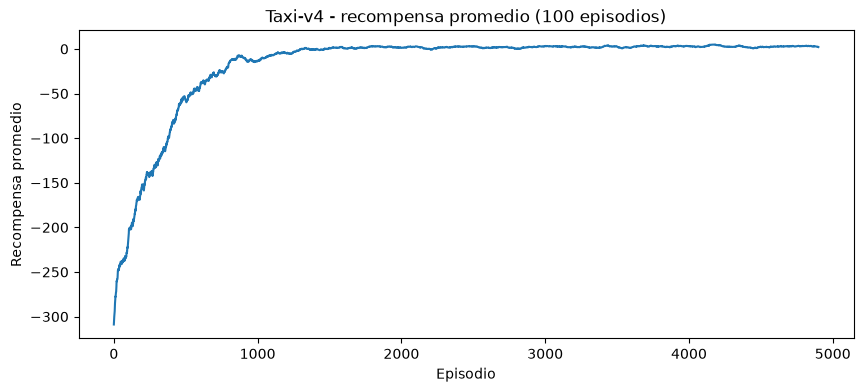

In [14]:
window = 100

moving_average = np.convolve(
    rewards,
    np.ones(window) / window,
    mode="valid"
)

plt.figure(figsize=(10, 4))
plt.plot(moving_average)
plt.xlabel("Episodio")
plt.ylabel("Recompensa promedio")
plt.title(f"Taxi-v4 - recompensa promedio ({window} episodios)")
plt.show()


In [15]:
# Números detrás de la curva (solo lee `rewards`, no usa azar).
for a, b in [(0, 100), (100, 500), (500, 1000), (1000, 2000), (2000, 5000)]:
    print(f"episodios {a:4d}-{b:4d}: recompensa media {np.mean(rewards[a:b]):8.2f}")

# Primer episodio en el que la media móvil de 100 episodios supera 0 y primer episodio en que
# queda a menos de 2 puntos de su valor final.
final = np.mean(rewards[-1000:])
primero_positivo = int(np.argmax(moving_average > 0)) + window
cerca_final = int(np.argmax(np.abs(moving_average - final) < 2)) + window
print(f"\nMedia de los últimos 1000 episodios: {final:.2f} (desv {np.std(rewards[-1000:]):.2f})")
print(f"Media móvil > 0 por primera vez cerca del episodio {primero_positivo}")
print(f"Media móvil dentro de 2 puntos del valor final por primera vez cerca del episodio {cerca_final}")
print(f"Peor episodio de los últimos 1000: {min(rewards[-1000:])}")

episodios    0- 100: recompensa media  -308.85
episodios  100- 500: recompensa media  -146.38
episodios  500-1000: recompensa media   -30.79
episodios 1000-2000: recompensa media    -1.79
episodios 2000-5000: recompensa media     2.36

Media de los últimos 1000 episodios: 2.75 (desv 7.89)
Media móvil > 0 por primera vez cerca del episodio 1403
Media móvil dentro de 2 puntos del valor final por primera vez cerca del episodio 1428
Peor episodio de los últimos 1000: -40


**Respuesta.**

- **¿Mejora la recompensa promedio?** Sí, de forma muy marcada. Pasa de una media de -308.9 en los primeros 100 episodios (el taxi da vueltas hasta agotar los 200 pasos y comete muchos Pickup y Dropoff ilegales) a -146.4 entre los episodios 100 y 500, -30.8 entre 500 y 1000, -1.8 entre 1000 y 2000, y +2.4 entre 2000 y 5000.
- **¿Cuándo se estabiliza?** La media móvil de 100 episodios cruza el 0 hacia el episodio 1403 y queda a menos de 2 puntos de su valor final hacia el episodio 1428. Es decir, **a partir de unos 1400 episodios** la curva es prácticamente plana.
- **¿Convergencia perfecta o política razonablemente buena?** Solo **una política razonablemente buena**. La media de los últimos 1000 episodios es 2.75 con desviación 7.89, y todavía hay episodios malos (el peor de los últimos 1000 es -40). La razón es que durante el entrenamiento el agente sigue explorando con $\epsilon=0.1$, y una acción aleatoria a mitad de camino puede costar pasos o un Pickup/Dropoff ilegal (-10). La política *greedy* aprendida es mucho mejor que lo que muestra la curva: en la evaluación del experimento de la Pregunta 7 completa la tarea en el 100 % de 200 episodios con una recompensa media cercana a 8. Esa es la diferencia entre la recompensa de entrenamiento (con exploración) y la de evaluación (sin ella).

## 10. Reproducir un episodio

La siguiente función ejecuta una política greedy usando la Q-table aprendida y guarda los frames del episodio.


In [16]:
def play_episode(env, Q, max_steps=200, seed=None):
    state, _ = env.reset(seed=seed)

    frames = [env.render()]
    total_reward = 0

    for _ in range(max_steps):

        q_values = Q[state]
        max_q = np.max(q_values)

        best_actions = np.flatnonzero(q_values == max_q)
        action = int(np.random.choice(best_actions))

        next_state, reward, terminated, truncated, _ = env.step(action)

        frames.append(env.render())

        total_reward += reward
        state = next_state

        if terminated or truncated:
            break

    return frames, total_reward


def frames_to_video(frames, interval=500):
    fig = plt.figure(figsize=(6, 4))
    plt.axis("off")

    image = plt.imshow(frames[0])

    def update(frame):
        image.set_data(frame)
        return [image]

    anim = animation.FuncAnimation(
        fig,
        update,
        frames=frames,
        interval=interval,
        blit=True,
        repeat=True
    )

    plt.close(fig)
    return HTML(anim.to_jshtml())


## 11. Comparar antes y después

Primero observe un Taxi sin entrenamiento usando una Q-table en cero.


In [17]:
frames_initial, reward_initial = play_episode(
    env,
    Q_initial,
    max_steps=50,
    seed=7
)

print("Recompensa total sin entrenamiento:", reward_initial)
frames_to_video(frames_initial, interval=500)


Recompensa total sin entrenamiento: -158


Ahora observe el agente entrenado.


In [18]:
frames_trained, reward_trained = play_episode(
    env,
    Q_trained,
    max_steps=200,
    seed=7
)

print("Recompensa total después del entrenamiento:", reward_trained)
frames_to_video(frames_trained, interval=500)


Recompensa total después del entrenamiento: 10


In [19]:
# Resumen de los dos episodios mostrados (se calcula de los frames ya guardados, sin usar azar).
for nombre, fr, rec in [("sin entrenar", frames_initial, reward_initial), ("entrenado  ", frames_trained, reward_trained)]:
    print(f"{nombre}: {len(fr) - 1:3d} pasos, recompensa total {rec}")

sin entrenar:  50 pasos, recompensa total -158
entrenado  :  11 pasos, recompensa total 10


**Respuesta.** Con la misma semilla de ambiente (`seed=7`) los dos episodios son muy distintos:

- **Sin entrenamiento** (Q en cero): el taxi se mueve al azar (todas las acciones empatan), da 50 pasos sin entregar nada y termina con recompensa -158 (en el resumen de arriba se ve la longitud: 50 pasos, que es el máximo que se le dio). **No completa la tarea.** Se queda dando vueltas y puede intentar recoger o soltar en lugares donde no se puede (-10 cada vez).
- **Entrenado**: completa la tarea en 11 pasos con recompensa total 10: diez pasos de -1 y la entrega final de +20 (10 x (-1) + 20 = 10). En el video se ve que va directo hacia el pasajero, lo recoge con Pickup cuando está sobre él, lo lleva al destino y hace el Dropoff exactamente ahí.
- **¿Evita acciones innecesarias?** En este episodio sí: no choca contra paredes ni hace Pickup o Dropoff ilegales; la recompensa de 10 con 11 pasos es consistente con una ruta casi óptima (cada paso extra restaría 1).
- **Evidencia visual de que aprendió:** el comportamiento deja de parecer aleatorio y se vuelve dirigido, con una secuencia clara de ir, recoger, ir y entregar; y la recompensa pasa de negativa a positiva, resultado de terminar el episodio con la entrega (+20).

## 12. Analizar la política aprendida

Seleccione un estado cualquiera y observe los valores aprendidos para sus seis acciones.


In [20]:
state = 123

print("Estado:", state)
print("Q-values:", Q_trained[state])
print("Mejor acción:", np.argmax(Q_trained[state]))


Estado: 123
Q-values: [-3.23577723 -2.87153024 -1.90959403  3.94947757 -6.41916212 -5.23005726]
Mejor acción: 3


In [21]:
nombres = ["South", "North", "East", "West", "Pickup", "Dropoff"]
fila_taxi, col_taxi, pasajero, destino = env.unwrapped.decode(state)
print(f"Estado {state}: taxi en (fila {fila_taxi}, col {col_taxi}), pasajero en {pasajero}, destino {destino}")
for n, v in zip(nombres, Q_trained[state]):
    print(f"  {n:7s}: {v:8.3f}")
print("Mejor acción:", nombres[int(np.argmax(Q_trained[state]))])

Estado 123: taxi en (fila 1, col 1), pasajero en 0, destino 3
  South  :   -3.236
  North  :   -2.872
  East   :   -1.910
  West   :    3.949
  Pickup :   -6.419
  Dropoff:   -5.230
Mejor acción: West


**Respuesta.** Estado seleccionado: **123**. Decodificado: el taxi está en la fila 1, columna 1, el pasajero espera en la estación 0 (Red, esquina superior izquierda) y el destino es la estación 3 (Blue).

1. **La acción con mayor Q es West** (3.949). Tiene sentido: el pasajero está en Red, en (0,0), y el taxi está en (1,1); hay que ir hacia la izquierda y luego subir. Las demás acciones valen menos (East -1.91, North -2.87, South -3.24) y Pickup (-6.42) y Dropoff (-5.23) son las peores porque son ilegales en esa casilla (el pasajero no está ahí) y castigan con -10.
2. **Un Q mayor significa que, desde ese estado, esa acción conduce a una mayor recompensa total esperada** (descontada) si después se sigue actuando bien. Comparar los $Q(s,\cdot)$ de una fila es comparar qué tan buena es cada decisión en ese estado; la política greedy escoge la de mayor valor.
3. **No es solo la recompensa inmediata** porque $Q(s,a)$ incluye todo lo que viene después: $Q(s,a)=r+\gamma\max_{a'}Q(s',a')$ (en esperanza). Ir al oeste da recompensa inmediata de -1, pero su valor es +3.949 porque acerca al taxi al pasajero y a la entrega de +20. Si Q fuera solo el reward inmediato, todos los movimientos valdrían -1 y no se distinguiría el buen camino del malo. Q propaga hacia atrás, paso a paso, el premio final de la entrega.

## 13. Experimentación

Modifique **solo uno** de los siguientes hiperparámetros y vuelva a entrenar:

- $\alpha$
- $\gamma$
- $\epsilon$

### Pregunta 7

Compare el nuevo entrenamiento con el original.

Explique cómo el cambio del hiperparámetro afectó:

- velocidad de aprendizaje,
- estabilidad,
- recompensa final,
- comportamiento observado.


alpha | media 1ros 500 | ep. estable | media ult. 1000 | desv ult. 1000 | eval greedy | % con exito
  0.1 |        -186.50 |        1473 |            2.40 |           7.80 |        7.96 |      100.0%
  0.5 |         -70.01 |         531 |            2.42 |           7.87 |        7.95 |      100.0%


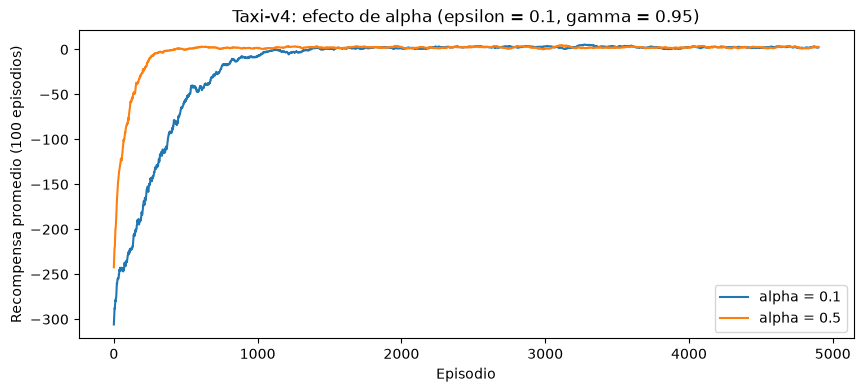

In [22]:
# Experimento de la Pregunta 7: se cambia SOLO alpha (0.1 -> 0.5). Todo lo demás igual.
# Cada entrenamiento usa un ambiente nuevo y las mismas semillas para que la comparación sea justa.
def entrenar_con_semilla(alpha, semilla=123, episodes=5000):
    with aislado():
        random.seed(semilla); np.random.seed(semilla)
        e = gym.make("Taxi-v4", render_mode="rgb_array")
        e.reset(seed=semilla); e.action_space.seed(semilla)
        Qx = np.zeros((e.observation_space.n, e.action_space.n))
        Qx, rw = train_q_learning(e, Qx, episodes=episodes, alpha=alpha, gamma=0.95, epsilon=0.1)
        # evaluación greedy sobre 200 episodios con semilla propia (desempate determinista con argmax)
        evals = []
        for k in range(200):
            s, _ = e.reset(seed=1000 + k)
            tot = 0
            for _ in range(200):
                s, r, term, trunc, _ = e.step(int(np.argmax(Qx[s])))
                tot += r
                if term or trunc:
                    break
            evals.append(tot)
    return Qx, np.array(rw), np.array(evals)

resultados = {a: entrenar_con_semilla(a) for a in (0.1, 0.5)}

filas = []
for a, (Qx, rw, ev) in resultados.items():
    ma = np.convolve(rw, np.ones(100) / 100, mode="valid")
    ep_estable = int(np.argmax(ma > ma[-1000:].mean() - 2)) + 100
    filas.append((a, np.mean(rw[:500]), ep_estable, np.mean(rw[-1000:]), np.std(rw[-1000:]), np.mean(ev), (ev > 0).mean()))
print(f"{'alpha':>5} | {'media 1ros 500':>14} | {'ep. estable':>11} | {'media ult. 1000':>15} | {'desv ult. 1000':>14} | {'eval greedy':>11} | {'% con exito':>11}")
for f in filas:
    print(f"{f[0]:5.1f} | {f[1]:14.2f} | {f[2]:11d} | {f[3]:15.2f} | {f[4]:14.2f} | {f[5]:11.2f} | {f[6]:11.1%}")

plt.figure(figsize=(10, 4))
for a, (Qx, rw, ev) in resultados.items():
    plt.plot(np.convolve(rw, np.ones(100) / 100, mode="valid"), label=f"alpha = {a}")
plt.xlabel("Episodio"); plt.ylabel("Recompensa promedio (100 episodios)")
plt.title("Taxi-v4: efecto de alpha (epsilon = 0.1, gamma = 0.95)")
plt.legend(); plt.show()

**Respuesta.** Modifiqué **solo $\alpha$**, de 0.1 a **0.5** (con $\gamma=0.95$, $\epsilon=0.1$ y 5000 episodios iguales). Para que la comparación fuera justa, ambos entrenamientos usan un ambiente nuevo y las mismas semillas; la tabla y la gráfica de arriba muestran los resultados:

| | $\alpha=0.1$ (original) | $\alpha=0.5$ |
|---|---:|---:|
| Media de los primeros 500 episodios | -186.5 | -70.0 |
| Episodio en que se estabiliza (media móvil cerca del final) | 1473 | 531 |
| Media de los últimos 1000 episodios | 2.40 | 2.42 |
| Desviación de los últimos 1000 | 7.80 | 7.87 |
| Evaluación greedy (200 episodios) | 7.96 | 7.95 |
| Episodios resueltos en la evaluación | 100 % | 100 % |

- **Velocidad de aprendizaje:** con $\alpha=0.5$ el aprendizaje es **bastante más rápido**: se estabiliza hacia el episodio 531 en vez del 1473, porque cada experiencia mueve $Q$ una fracción mayor del error TD y la información de la recompensa final se propaga hacia atrás con menos visitas.
- **Estabilidad:** en este ambiente **no se notó pérdida de estabilidad** con $\alpha=0.5$: la desviación de la recompensa en la fase final es prácticamente igual (7.87 contra 7.80). Eso se explica porque Taxi-v4 es determinístico, así que no hay ruido en las transiciones que un $\alpha$ grande amplifique. En un ambiente estocástico como FrozenLake resbaloso, un $\alpha$ alto sí introduce más variación (ver el notebook de FrozenLake).
- **Recompensa final:** prácticamente idéntica (2.42 contra 2.40 en entrenamiento, 7.95 contra 7.96 en evaluación greedy): ambas llegan a la misma política buena; la diferencia está en cuánto tardan.
- **Comportamiento observado:** las dos políticas entregan al pasajero en el 100 % de los 200 episodios de evaluación. El efecto de $\alpha$ fue sobre el *camino* de aprendizaje, no sobre el resultado final. Es un solo experimento con una sola semilla, así que la conclusión sobre velocidad es indicativa, no una prueba estadística.

## Entrega

El notebook debe contener:

1. implementación de `choose_action`;
2. implementación de `update_q`;
3. implementación de `train_q_learning`;
4. curva de aprendizaje;
5. visualización del agente antes y después del entrenamiento;
6. respuestas a las siete preguntas.

No es necesario modificar las funciones auxiliares de visualización.


## Resumen de entrega

Se implementaron `choose_action`, `update_q` y `train_q_learning`; se graficó la curva de aprendizaje (con los números que la respaldan); se visualizó el taxi antes y después del entrenamiento; y se respondieron las siete preguntas. Resultado principal: con $\alpha=0.1$, $\gamma=0.95$, $\epsilon=0.1$ el agente se estabiliza hacia el episodio 1400 y su política greedy resuelve el 100 % de los episodios de evaluación con recompensa media cercana a 8; con $\alpha=0.5$ llega al mismo lugar en unos 530 episodios.